# Зниження розмірності, кластеризація та класифікація текстів

Лабораторна робота № 2 · Гліб Плахтій


## 1. PCA і t-SNE

Використовуємо ті самі файли та шість класів `Activity`, що й у Lab 1. Один рядок описує вікно вимірювань акселерометра й гіроскопа за 2,56 с. Із 563 стовпців беремо 561 числову ознаку, а `Activity` використовуємо як ціль, `subject` - для перевірки поділу. [Kaggle](https://www.kaggle.com/datasets/uciml/human-activity-recognition-with-smartphones) · [UCI](https://archive.ics.uci.edu/dataset/240/human+activity+recognition+using+smartphones)

In [1]:
from io import BytesIO
from pathlib import Path
import re
import unicodedata
from time import perf_counter
from urllib.request import urlopen
from zipfile import ZipFile

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (
    accuracy_score, adjusted_rand_score, classification_report,
    confusion_matrix, f1_score, silhouette_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from threadpoolctl import threadpool_limits
from wordcloud import WordCloud

SEED = 42
LABELS = ["WALKING", "WALKING_UPSTAIRS", "WALKING_DOWNSTAIRS", "SITTING", "STANDING", "LAYING"]
DATASET = "uciml/human-activity-recognition-with-smartphones/versions/1"

def read_har_split(filename):
    for directory in (Path("data/har"), Path("../lab 1/data/har")):
        local = directory / filename
        if local.is_file():
            return pd.read_csv(local)
    downloaded = Path(kagglehub.dataset_download(DATASET, path=filename))
    return pd.read_csv(downloaded / filename if downloaded.is_dir() else downloaded)

train, test = read_har_split("train.csv"), read_har_split("test.csv")
features = train.columns.drop(["Activity", "subject"])
X_train, X_test = train[features], test[features]
y_train, y_test = train["Activity"], test["Activity"]
assert set(train["subject"]).isdisjoint(test["subject"])
display(pd.DataFrame({"Train": y_train.value_counts(), "Test": y_test.value_counts()}).loc[LABELS])
print("Input features:", len(features))

,Train,Test
Activity,,
WALKING,1226,496
WALKING_UPSTAIRS,1073,471
WALKING_DOWNSTAIRS,986,420
SITTING,1286,491
STANDING,1374,532
LAYING,1407,537


Input features: 561


### Порівняння SVM із PCA та без PCA

Беремо RBF-SVM з Lab 1 (`C=100`, `gamma=0.0003`). Обидві версії використовують `StandardScaler` і однакові тестові метрики, macro F1 та accuracy. Число компонент визначає `PCA(n_components=0.95)` за навчальною вибіркою. Поріг зберігає щонайменше 95% дисперсії стандартизованих ознак. Масштабування та PCA навчаються в pipeline. Для відтворюваного заміру робимо три повні запуски `fit` кожного варіанта й беремо медіану. Порядок запусків чергується, числові бібліотеки обмежені одним потоком.

In [2]:
svc = SVC(kernel="rbf", C=100, gamma=0.0003)
pipelines = {
    "Without PCA": make_pipeline(StandardScaler(), clone(svc)),
    "With PCA": make_pipeline(StandardScaler(), PCA(n_components=0.95, svd_solver="full"), clone(svc)),
}
timings = {name: [] for name in pipelines}
fitted = {}
with threadpool_limits(limits=1):
    for repeat in range(3):
        names = list(pipelines)
        for name in (names if repeat % 2 == 0 else names[::-1]):
            model = clone(pipelines[name])
            start = perf_counter()
            model.fit(X_train, y_train)
            timings[name].append(perf_counter() - start)
            fitted[name] = model

pca = fitted["With PCA"].named_steps["pca"]
dimension = X_train.shape[1]
results = []
for name, model in fitted.items():
    prediction = model.predict(X_test)
    components = pca.n_components_ if name == "With PCA" else dimension
    results.append({
        "Pipeline": name,
        "Input features": dimension,
        "Model dimensions": components,
        "Dimensions removed": dimension - components,
        "Reduction (%)": 100 * (1 - components / dimension),
        "Explained variance (%)": 100 * pca.explained_variance_ratio_.sum() if name == "With PCA" else np.nan,
        "Test macro F1": f1_score(y_test, prediction, labels=LABELS, average="macro"),
        "Test accuracy": accuracy_score(y_test, prediction),
        "Median fit (s)": np.median(timings[name]),
    })
pca_results = pd.DataFrame(results).set_index("Pipeline")
display(pca_results.round(4))
difference = pca_results.loc["With PCA"] - pca_results.loc["Without PCA"]
display(difference[["Test macro F1", "Test accuracy", "Median fit (s)"]].rename("With PCA minus without PCA").round(4))

,Input features,Model dimensions,Dimensions removed,Reduction (%),Explained variance (%),Test macro F1,Test accuracy,Median fit (s)
Pipeline,,,,,,,,
Without PCA,561,561,0,0.0000,NaN,0.9589,0.9593,0.4944
With PCA,561,102,459,81.8182,95.0756,0.9291,0.9308,0.6154


Test macro F1    -0.0299
Test accuracy    -0.0285
Median fit (s)    0.1211
Name: With PCA minus without PCA, dtype: float64

Рядок `With PCA minus without PCA` показує вплив PCA при тих самих параметрах SVM. Від’ємна різниця для macro F1 означає нижчу якість, а від’ємна різниця для часу означає швидший повний `fit`. Збережена дисперсія описує варіацію ознак, тому сама по собі не гарантує збереження інформації про клас.

### Проєкція t-SNE

Випадково відбираємо 1 800 вікон із train без використання класів, щоб скоротити час проєкції. Для t-SNE попередньо стискаємо стандартизовані ознаки до 50 компонент. Використовуємо `perplexity=30`. Класи додаємо після проєкції. Порівнюємо передусім близьких сусідів, оскільки відстані між далекими групами та розміри груп у t-SNE можуть спотворюватися.

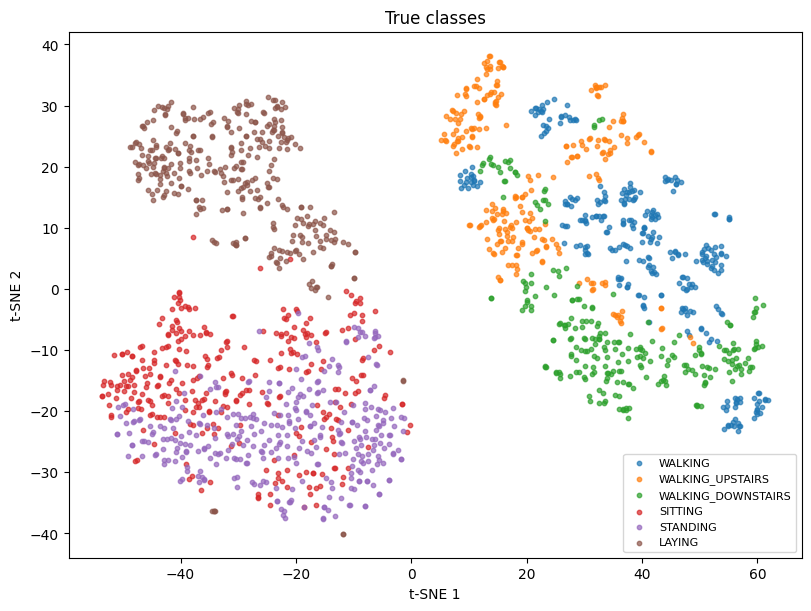

In [3]:
sample = X_train.sample(n=1800, random_state=SEED)
with threadpool_limits(limits=1):
    embedding_input = make_pipeline(
        StandardScaler(), PCA(n_components=50, svd_solver="randomized", random_state=SEED)
    ).fit_transform(sample)
    coordinates = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(embedding_input)

sample_labels = y_train.loc[sample.index].to_numpy()

def plot_map(ax, positions, groups, order, title):
    for group in order:
        points = positions[groups == group]
        ax.scatter(points[:, 0], points[:, 1], s=10, alpha=0.7, label=str(group))
    ax.set(title=title, xlabel="t-SNE 1", ylabel="t-SNE 2")
    ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
plot_map(ax, coordinates, sample_labels, LABELS, "True classes")
plt.show()

На карті перевіряємо, де сусідять різні класи. Для кількісного опису підрахуємо частку п’яти найближчих сусідів того самого класу у 2D для кожної мітки. Низька частка вказує на локальне змішування саме в цій проєкції.

In [4]:
neighbor_indices = NearestNeighbors(n_neighbors=5).fit(coordinates).kneighbors(return_distance=False)
agreement = (sample_labels[neighbor_indices] == sample_labels[:, None]).mean(axis=1)
local_agreement = pd.Series(agreement).groupby(sample_labels).mean().reindex(LABELS)
display(local_agreement.rename("Same-class neighbors").round(3))
print("Class with most mixed neighborhoods:", local_agreement.idxmin())

WALKING               0.974
WALKING_UPSTAIRS      0.958
WALKING_DOWNSTAIRS    0.943
SITTING               0.729
STANDING              0.786
LAYING                0.976
Name: Same-class neighbors, dtype: float64

Class with most mixed neighborhoods: SITTING


## 2. K-Means

Кластеризуємо ті самі 1 800 навчальних вікон у просторі 50 компонент PCA. Зберігаємо всі представлені класи, а підвибірка визначена без міток. `Activity` та `subject` відсутні у вхідному просторі. Перебираємо `k` від 2 до 10. Вибираємо найбільший silhouette, який порівнює компактність кластера з відділеністю від сусідніх кластерів. Використовуємо модель з обраним `k` у тому самому просторі. Inertia показано додатково для перевірки, де сповільнюється її спад.

,Inertia,Silhouette
k,,
2,454840.5169,0.4485
3,391409.2161,0.3795
4,364650.7923,0.2054
5,340303.3557,0.1727
6,326686.0192,0.1476
7,313814.1284,0.1416
8,303040.0194,0.1232
9,292304.6847,0.1296
10,283641.0179,0.1231


Selected k: 2


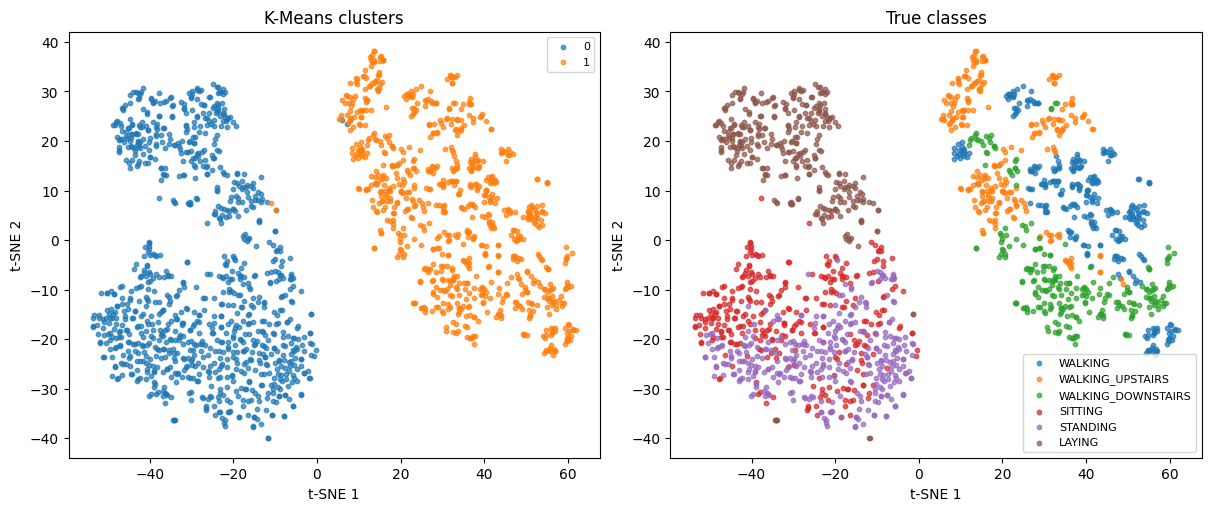

In [5]:
cluster_models = {}
scores = []
with threadpool_limits(limits=1):
    for k in range(2, 11):
        model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(embedding_input)
        cluster_models[k] = model
        scores.append({
            "k": k,
            "Inertia": model.inertia_,
            "Silhouette": silhouette_score(embedding_input, model.labels_),
        })

cluster_scores = pd.DataFrame(scores).set_index("k")
best_k = cluster_scores["Silhouette"].idxmax()
clusters = cluster_models[best_k].labels_
display(cluster_scores.round(4))
print("Selected k:", best_k)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
plot_map(axes[0], coordinates, clusters, range(best_k), "K-Means clusters")
plot_map(axes[1], coordinates, sample_labels, LABELS, "True classes")
plt.show()

### Відповідність кластерів класам

Мітки залучаємо тепер для оцінки. Рядок таблиці показує склад кластера, а стовпець - розподіл класу між кластерами. Стовпець `Dominant cluster share` показує, яка частка класу потрапила до його найбільшого кластера. Два класи зі спільним домінантним кластером можуть змішуватися. Мала частка означає, що клас розподілений між кількома кластерами. ARI не залежить від нумерації кластерів. Значення близьке до нуля означає відповідність на рівні випадкового поділу, а 1 відповідає збігу.

In [6]:
composition = pd.crosstab(
    pd.Series(clusters, name="Cluster"),
    pd.Series(sample_labels, name="Activity"),
).reindex(columns=LABELS, fill_value=0)
display(composition)
dominance = pd.DataFrame({
    "Dominant cluster": composition.idxmax(),
    "Dominant cluster share": composition.max() / composition.sum(),
})
display(dominance.round(3))
print(f"Adjusted Rand index: {adjusted_rand_score(sample_labels, clusters):.4f}")

Activity,WALKING,WALKING_UPSTAIRS,WALKING_DOWNSTAIRS,SITTING,STANDING,LAYING
Cluster,,,,,,
0,0,2,0,320,343,335
1,298,248,252,0,0,2


,Dominant cluster,Dominant cluster share
Activity,,
WALKING,1,1.000
WALKING_UPSTAIRS,1,0.992
WALKING_DOWNSTAIRS,1,1.000
SITTING,0,1.000
STANDING,0,1.000
LAYING,0,0.994


Adjusted Rand index: 0.3282


## 3. Класифікація SMS

Використовуємо англомовні повідомлення з двома мітками `ham` і `spam`. Файл містить лише мітку та текст. Ознакою слугує лише текст. Ноутбук завантажує архів UCI, а для локального запуску приймає розпакований файл `data/SMSSpamCollection`. [SMS Spam Collection, UCI](https://archive.ics.uci.edu/dataset/228/sms+spam+collection)

Нормалізуємо Unicode та регістр, а пунктуацію замінюємо межами слів. Зберігаємо цифри й стоп-слова, бо в коротких SMS числа та звичайні слова можуть бути інформативними. Перевіряємо пропуски й порожні повідомлення. Дублікати шукаємо після нормалізації. Повідомлення із суперечливими мітками видаляємо, а з решти повторів залишаємо один примірник. Це унеможливлює перетин нормалізованих текстів між вибірками. Офіційного поділу немає, тому робимо стратифікований поділ 80/20.

In [7]:
SMS_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
SMS_LABELS = ["ham", "spam"]

def normalize_sms(message):
    normalized = unicodedata.normalize("NFKC", message).casefold()
    return " ".join(re.findall(r"[^\W_]{2,}", normalized))

sms_path = Path("data/SMSSpamCollection")
if sms_path.is_file():
    raw_sms = sms_path.read_text(encoding="utf-8")
else:
    with urlopen(SMS_URL, timeout=30) as response, ZipFile(BytesIO(response.read())) as archive:
        raw_sms = archive.read("SMSSpamCollection").decode("utf-8")

sms = pd.DataFrame(
    [line.split("\t", 1) for line in raw_sms.splitlines()],
    columns=["label", "text"],
)
original_label_counts = sms["label"].value_counts()
missing = sms.isna().sum()
assert set(sms["label"].dropna()) == set(SMS_LABELS)
sms = sms.dropna(subset=["label", "text"]).copy()
sms["normalized"] = sms["text"].map(normalize_sms)
empty = sms["normalized"].eq("")
sms = sms.loc[~empty].copy()
label_counts = sms.groupby("normalized")["label"].nunique()
conflicts = sms["normalized"].isin(label_counts[label_counts > 1].index)
sms = sms.loc[~conflicts].copy()
duplicates = sms["normalized"].duplicated()
print("Missing values:", missing.to_dict())
print("Empty after normalization:", int(empty.sum()))
print("Rows with conflicting labels:", int(conflicts.sum()))
print("Repeated rows after conflict removal:", int(duplicates.sum()))
sms = sms.loc[~duplicates].copy()

text_train, text_test, spam_train, spam_test = train_test_split(
    sms["normalized"], sms["label"], test_size=0.2, stratify=sms["label"], random_state=SEED
)
assert set(text_train).isdisjoint(text_test)
display(pd.DataFrame({
    "Original": original_label_counts,
    "Train": spam_train.value_counts(), "Test": spam_test.value_counts(),
}).loc[SMS_LABELS])

Missing values: {'label': 0, 'text': 0}
Empty after normalization: 4
Rows with conflicting labels: 0
Repeated rows after conflict removal: 445


,Original,Train,Test
label,,,
ham,4827,3597,899
spam,747,503,126


### WordCloud і модель

Для кожної хмари рахуємо, скільки тренувальних повідомлень класу містять слово. Повтори всередині одного SMS не збільшують вагу. На хмарах і в таблиці порівнюємо найпоширеніші слова класів. Спільні часті слова можуть займати багато місця в обох хмарах. TF-IDF зменшує вагу слів, поширених у багатьох документах.

Для класифікації використовуємо TF-IDF зі словами й біграмами та логістичну регресію. Словник та IDF навчаються лише на train. Accuracy показує загальну частку правильних прогнозів, а macro F1 дає однакову вагу `ham` і `spam` попри їх різний розмір.

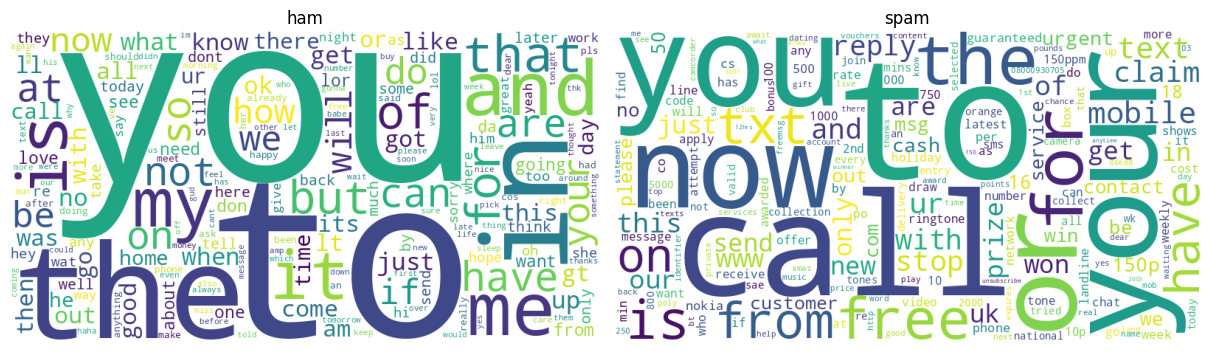

,ham,spam
0,you,to
1,to,call
2,the,you
3,in,your
4,and,now
5,me,or
6,my,the
7,is,for
8,it,free
9,that,is


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
top_terms = {}
for ax, label in zip(axes, SMS_LABELS):
    vectorizer = CountVectorizer(binary=True, lowercase=False)
    counts = vectorizer.fit_transform(text_train[spam_train == label])
    frequencies = pd.Series(np.asarray(counts.sum(axis=0)).ravel(), index=vectorizer.get_feature_names_out())
    top_terms[label] = frequencies.nlargest(10).index.tolist()
    cloud = WordCloud(width=800, height=420, background_color="white", random_state=SEED)
    ax.imshow(cloud.generate_from_frequencies(frequencies.to_dict()))
    ax.set_title(label)
    ax.axis("off")
plt.show()
display(pd.DataFrame(top_terms))

In [9]:
spam_model = make_pipeline(
    TfidfVectorizer(lowercase=False, ngram_range=(1, 2), min_df=2, sublinear_tf=True),
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED),
)
spam_model.fit(text_train, spam_train)
spam_prediction = spam_model.predict(text_test)
print(f"Accuracy: {accuracy_score(spam_test, spam_prediction):.4f}")
print(f"Macro F1: {f1_score(spam_test, spam_prediction, labels=SMS_LABELS, average='macro'):.4f}")
print(classification_report(spam_test, spam_prediction, labels=SMS_LABELS, digits=4, zero_division=0))
sms_matrix = confusion_matrix(spam_test, spam_prediction, labels=SMS_LABELS)
display(pd.DataFrame(sms_matrix, index=pd.Index(SMS_LABELS, name="Actual"),
                     columns=pd.Index(SMS_LABELS, name="Prediction")))
print(f"False alarms (ham -> spam): {sms_matrix[0, 1]}")
print(f"Missed spam (spam -> ham): {sms_matrix[1, 0]}")

Accuracy: 0.9815
Macro F1: 0.9566
              precision    recall  f1-score   support

         ham     0.9878    0.9911    0.9895       899
        spam     0.9350    0.9127    0.9237       126

    accuracy                         0.9815      1025
   macro avg     0.9614    0.9519    0.9566      1025
weighted avg     0.9813    0.9815    0.9814      1025



Prediction,ham,spam
Actual,,
ham,891,8
spam,11,115


False alarms (ham -> spam): 8
Missed spam (spam -> ham): 11


Для оцінки помилок порівнюємо дві клітинки поза діагоналлю. `ham` → `spam` означає, що фільтр відхилив звичайне повідомлення. `spam` → `ham` означає, що фільтр пропустив спам. Через різні розміри класів порівнюємо і кількості, і повноту за кожною міткою.